# Assignment 6: Air sensor bias correction model validation

Low-cost air quality sensors are cheap enough to deploy in dense networks, but their raw
readings are not accurate. The usual fix is **calibration**: put the cheap sensor next to a
reference-grade instrument, learn a mapping from one to the other, and apply that mapping
to new readings. That mapping is a machine learning model. Validating it properly is harder
than it looks, and that is the real subject of this assignment.

You will use the dataset of De Vito et al. (2008): five low-cost gas sensors run for about
a year next to reference analyzers in an Italian city.

Answer each numbered question in the empty cell below it.

In [1]:
import io
import urllib.request
import zipfile

import numpy as np
import pandas as pd
import matplotlib.pyplot as plt

from sklearn.linear_model import LinearRegression
from sklearn.ensemble import RandomForestRegressor
from sklearn.model_selection import train_test_split
from sklearn.metrics import mean_squared_error, r2_score

## Load the data

The archive is hosted by the UCI Machine Learning Repository. Missing values are coded
`-200`, which we convert to `NaN` on load. If you leave them in, every model you fit will
be quietly ruined.

In [2]:
url = "https://archive.ics.uci.edu/static/public/360/air+quality.zip"
with urllib.request.urlopen(url) as resp:
    archive = zipfile.ZipFile(io.BytesIO(resp.read()))

# European CSV conventions: semicolon separator, comma decimal mark.
aq = pd.read_csv(archive.open("AirQualityUCI.csv"), sep=";", decimal=",",
                 usecols=range(15), na_values=[-200])
aq = aq.dropna(how="all")

aq["datetime"] = pd.to_datetime(
    aq["Date"] + " " + aq["Time"].str.replace(".", ":", regex=False),
    format="%d/%m/%Y %H:%M:%S")
aq = aq.sort_values("datetime").reset_index(drop=True)

print(f"{len(aq)} hourly records, {aq.datetime.min()} to {aq.datetime.max()}")
aq.head()

9357 hourly records, 2004-03-10 18:00:00 to 2005-04-04 14:00:00


,Date,Time,CO(GT),PT08.S1(CO),NMHC(GT),C6H6(GT),PT08.S2(NMHC),NOx(GT),PT08.S3(NOx),NO2(GT),PT08.S4(NO2),PT08.S5(O3),T,RH,AH,datetime
0,10/03/2004,18.00.00,2.6,1360.0,150.0,11.9,1046.0,166.0,1056.0,113.0,1692.0,1268.0,13.6,48.9,0.7578,2004-03-10 18:00:00
1,10/03/2004,19.00.00,2.0,1292.0,112.0,9.4,955.0,103.0,1174.0,92.0,1559.0,972.0,13.3,47.7,0.7255,2004-03-10 19:00:00
2,10/03/2004,20.00.00,2.2,1402.0,88.0,9.0,939.0,131.0,1140.0,114.0,1555.0,1074.0,11.9,54.0,0.7502,2004-03-10 20:00:00
3,10/03/2004,21.00.00,2.2,1376.0,80.0,9.2,948.0,172.0,1092.0,122.0,1584.0,1203.0,11.0,60.0,0.7867,2004-03-10 21:00:00
4,10/03/2004,22.00.00,1.6,1272.0,51.0,6.5,836.0,131.0,1205.0,116.0,1490.0,1110.0,11.2,59.6,0.7888,2004-03-10 22:00:00


The columns divide into three groups:

- **`PT08.S1` through `PT08.S5`**: the raw responses of the five low-cost sensors.
  These are the cheap instrument.
- **`CO(GT)`, `NMHC(GT)`, `C6H6(GT)`, `NOx(GT)`, `NO2(GT)`**: the co-located reference
  analyzer values. `GT` stands for ground truth. This is what you are trying to predict.
- **`T`, `RH`, `AH`**: temperature, relative humidity, absolute humidity.

We will focus on **NOx**: sensor `PT08.S3(NOx)` against reference `NOx(GT)`.

## Part 1: How bad is the raw sensor?

1) Plot the raw sensor response `PT08.S3(NOx)` against the reference `NOx(GT)` and compute
the correlation. Is the relationship positive or negative? Does it look linear?

Correlation: -0.656


Text(0, 0.5, 'Reference (NOx(GT))(ppb)')

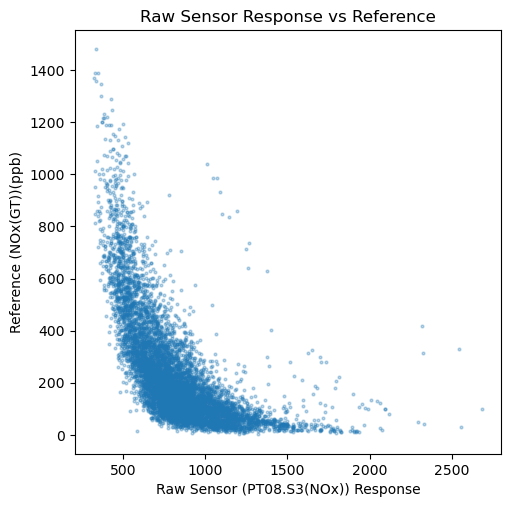

In [3]:
fig, ax = plt.subplots(figsize=(5.5, 5.5))

sensor = aq['PT08.S3(NOx)']
reference = aq['NOx(GT)']

corr = sensor.corr(reference)
print(f"Correlation: {corr:.3f}")

ax.scatter(sensor,reference, s=4, alpha=0.3)

ax.set_title("Raw Sensor Response vs Reference")
ax.set_xlabel("Raw Sensor (PT08.S3(NOx)) Response")
ax.set_ylabel("Reference (NOx(GT))(ppb)")

_The relationship is negative, with a correlation of -0.656 between PT08.S3(NOx) and NOx(GT). It does not look linear, but rather appears to be an inverse non-linear relationship. This tells us that the higher reference NOX levels result in lower raw sensor NOX values._

2) Plot both series against time for a two-week window. Do they track each other?

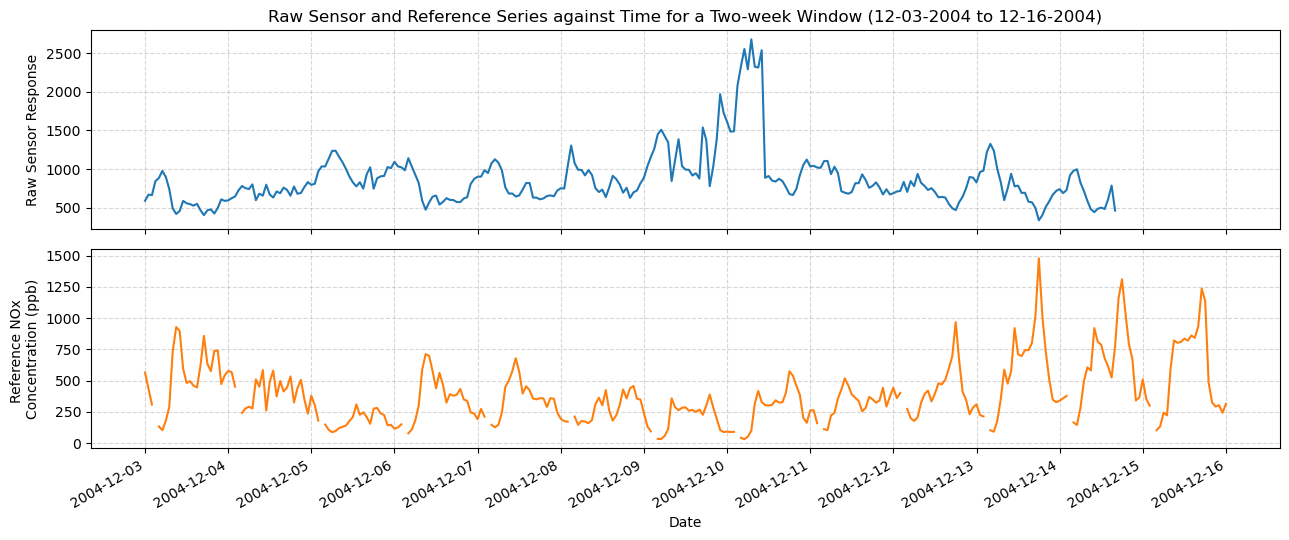

In [4]:
import matplotlib.dates as mdates
import matplotlib.pyplot as plt
import pandas as pd

fig, (ax1, ax2) = plt.subplots(2,1,figsize=(13, 5.5), sharex=True)

combined_text = aq["Date"].astype(str) + " " + aq["Time"].astype(str)
aq["datetime_fixed"] = pd.to_datetime(combined_text, format="%d/%m/%Y %H.%M.%S")

aq_slice = aq[(aq["datetime_fixed"] >= "2004-12-03") & (aq["datetime_fixed"] <= "2004-12-16")]

ax1.plot(aq_slice["datetime_fixed"], aq_slice["PT08.S3(NOx)"], label="Raw Sensor Response")
ax1.set_title("Raw Sensor and Reference Series against Time for a Two-week Window (12-03-2004 to 12-16-2004)")
ax1.set_xlabel("Date")
ax1.set_ylabel("Raw Sensor Response")
ax1.grid(True, linestyle='--', alpha=0.5)

ax2.plot(aq_slice["datetime_fixed"], aq_slice["NOx(GT)"],color='tab:orange', label="Reference")
ax2.set_xlabel("Date")
ax2.set_ylabel("Reference NOx \nConcentration (ppb)")
ax2.grid(True, linestyle='--', alpha=0.5)
ax2.xaxis.set_major_locator(mdates.DayLocator(interval=1))

fig.autofmt_xdate()

plt.tight_layout()
plt.show()

_The raw sensor and the reference appear to track each other in opposite directions, with the raw sensor values increasing as the reference values are decreasing, and vice versa._

3) How many hours have a valid reading for both sensor and reference? What fraction of the deployment is that, and what does the pattern of missingness look like over time?

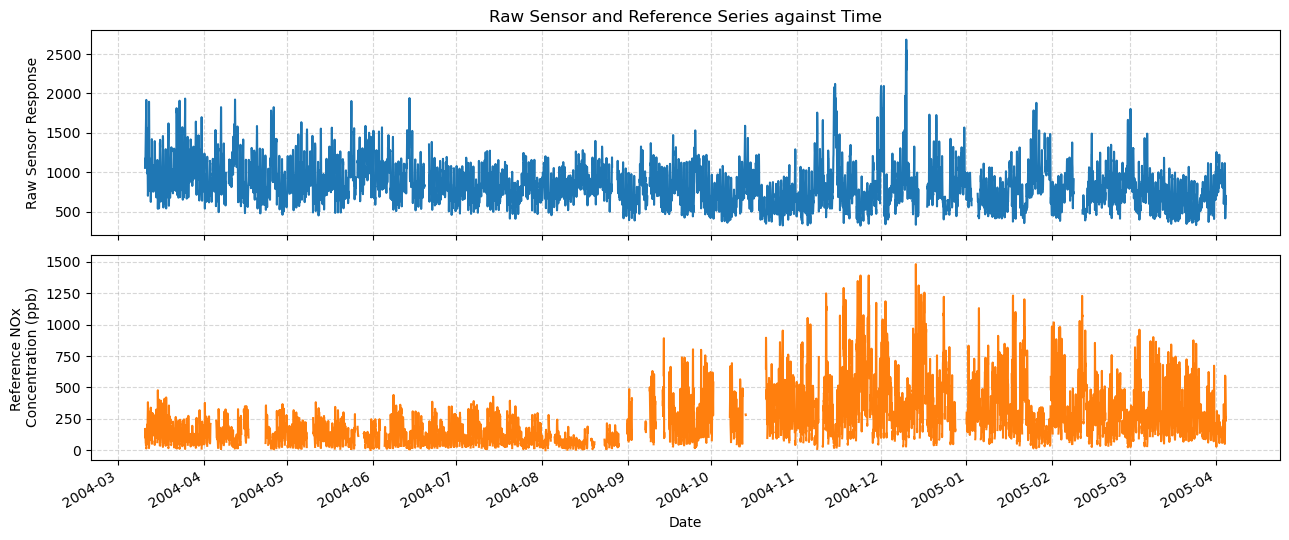

In [5]:
fig, (ax1, ax2) = plt.subplots(2,1,figsize=(13, 5.5), sharex=True)

ax1.plot(aq["datetime_fixed"], aq["PT08.S3(NOx)"], label="Raw Sensor Response")
ax1.set_title("Raw Sensor and Reference Series against Time")
ax1.set_xlabel("Date")
ax1.set_ylabel("Raw Sensor Response")
ax1.grid(True, linestyle='--', alpha=0.5)

ax2.plot(aq["datetime_fixed"], aq["NOx(GT)"],color='tab:orange', label="Reference")
ax2.set_xlabel("Date")
ax2.set_ylabel("Reference NOx \nConcentration (ppb)")
ax2.grid(True, linestyle='--', alpha=0.5)

ax2.xaxis.set_major_locator(mdates.MonthLocator(interval=1))

fig.autofmt_xdate()

plt.tight_layout()
plt.show()

In [6]:
valid_hours = aq[aq["PT08.S3(NOx)"].notna() & aq["NOx(GT)"].notna()]
valid_count = len(valid_hours)

print(f"Hours with valid data for both sensor and reference: {valid_count} hours")

total_count = len(aq)
print(f"Total hours of deployment: {total_count} hours")

fraction =  valid_count / total_count

print(f"Fraction of deployment: {fraction:.3f}")

Hours with valid data for both sensor and reference: 7396 hours
Total hours of deployment: 9357 hours
Fraction of deployment: 0.790


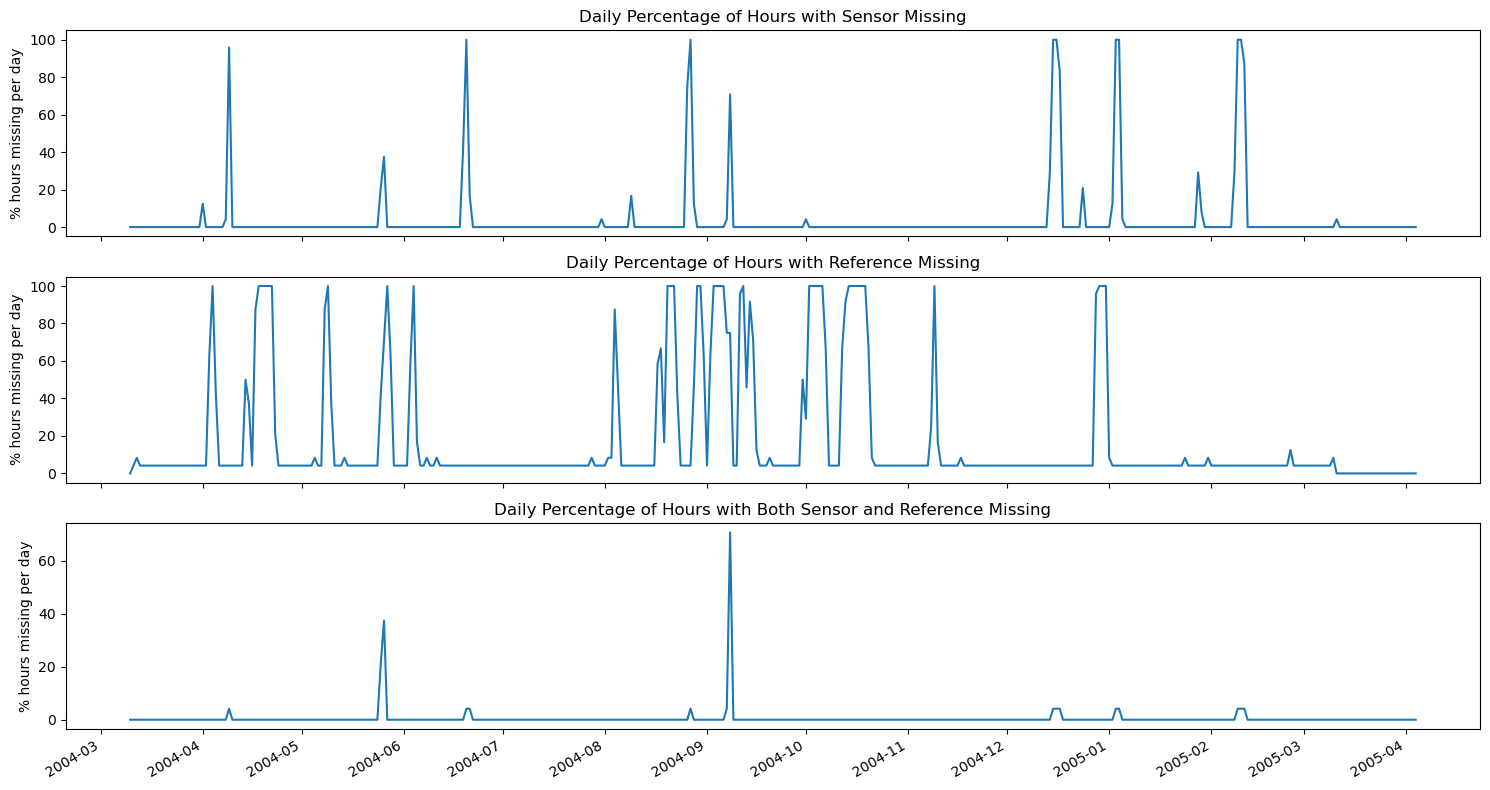

In [7]:
aq["datetime_fixed"] = pd.to_datetime(aq["datetime_fixed"])
aq_indexed = aq.set_index("datetime_fixed")

sensor_missing_daily = (aq_indexed["PT08.S3(NOx)"].isna()).resample("D").mean() * 100
reference_missing_daily = (aq_indexed["NOx(GT)"].isna()).resample("D").mean() * 100
both_missing_daily = (aq_indexed["PT08.S3(NOx)"].isna() & aq_indexed["NOx(GT)"].isna()).resample("D").mean() * 100

fig, (ax1, ax2, ax3) = plt.subplots(3, 1, figsize=(15, 8), sharex=True)

ax1.plot(sensor_missing_daily.index, sensor_missing_daily)
ax1.set_title("Daily Percentage of Hours with Sensor Missing")
ax1.set_ylabel("% hours missing per day")

ax2.plot(reference_missing_daily.index, reference_missing_daily)
ax2.set_title("Daily Percentage of Hours with Reference Missing")
ax2.set_ylabel("% hours missing per day")

ax3.plot(both_missing_daily.index, both_missing_daily)
ax3.set_title("Daily Percentage of Hours with Both Sensor and Reference Missing")
ax3.set_ylabel("% hours missing per day")

ax3.xaxis.set_major_locator(mdates.MonthLocator(interval=1))

fig.autofmt_xdate()

plt.tight_layout()
plt.show()

_Hours with valid data for both sensor and reference: 7396 hours._
_Total hours of deployment: 9357 hours._
_Fraction of deployment with a valid reading for both sensor and reference: 0.790._

_The pattern of missingness for just the sensor includes occassional missing data throughout the time period. Missing data was brief and sporadic._

_The pattern of missingness for just the reference includes occassional missing data throughout the time period, including frequently in the time periods of April 2004 to June 2004 and August 2004 to November 2004. It seems like the reference instrument would occasionally be out for a few days at a time._

_The pattern of missingness for both sensor and reference includes missing values around May/June of 2004, missing values around September 2004. Missing values for both sensor and reference at the same time appeared to be quite rare._



## Part 2: Baselines

Before fitting anything, establish what has to be beaten.

4) **Baseline 1, raw sensor.** The raw sensor is in the wrong units entirely, so scoring it
directly is meaningless. Instead, fit a single-variable linear regression from
`PT08.S3(NOx)` to `NOx(GT)` on the full dataset, and report RMSE and $R^2$. This is the
simplest possible calibration.

In [8]:
X = valid_hours[['PT08.S3(NOx)']] # raw sensor response
y = valid_hours['NOx(GT)'] # reference

print('Results for fitting a single-variable linear regression from PT08.S3(NOx) to NOx(GT) on the full dataset:')

model = LinearRegression()

model.fit(X, y)

y_pred = model.predict(X)

def rmse(truth, pred):
    return np.sqrt(np.mean((truth - pred) ** 2))
rmse_val = rmse(y, y_pred)
print(f"RMSE: {rmse_val:.2f} ppb")

r2 = r2_score(y, y_pred)
print(f"R-squared score: {r2:.2f}")

Results for fitting a single-variable linear regression from PT08.S3(NOx) to NOx(GT) on the full dataset:
RMSE: 155.76 ppb
R-squared score: 0.43


5) **Baseline 2, predict the mean.** Report the RMSE of always predicting the mean reference NOx. Any model scoring worse than this is worse than useless.

In [9]:
print('Results for always predicting the mean reference NOx:')

y_mean_reference = y.mean()

rmse_mean_ref = rmse(y, y_mean_reference)
print(f"RMSE: {rmse_mean_ref:.2f} ppb")


y_mean_ref_array = np.full_like(y, y_mean_reference)

r2_mean_ref = r2_score(y, y_mean_ref_array)
print(f"R-squared score: {r2_mean_ref:.2f}")

Results for always predicting the mean reference NOx:
RMSE: 206.30 ppb
R-squared score: 0.00


## Part 3: A better correction model

The other sensor channels and the weather variables may also carry information about NOx.
A correction using more inputs should do better.

6) Build a feature matrix from all five `PT08.S*` sensor channels plus `T`, `RH` and `AH`,
with `NOx(GT)` as the target. Drop rows with missing values and report how many remain.

In [10]:
aq.columns

Index(['Date', 'Time', 'CO(GT)', 'PT08.S1(CO)', 'NMHC(GT)', 'C6H6(GT)',
       'PT08.S2(NMHC)', 'NOx(GT)', 'PT08.S3(NOx)', 'NO2(GT)', 'PT08.S4(NO2)',
       'PT08.S5(O3)', 'T', 'RH', 'AH', 'datetime', 'datetime_fixed'],
      dtype='object')

In [11]:
feature_columns = ['PT08.S1(CO)', 'PT08.S2(NMHC)', 'PT08.S3(NOx)', 'PT08.S4(NO2)',
       'PT08.S5(O3)', 'T', 'RH', 'AH']

target_column = 'NOx(GT)'

variables = ['datetime_fixed'] + feature_columns + [target_column]

clean_aq = aq[variables].dropna().copy()
clean_aq['datetime_fixed'] = pd.to_datetime(clean_aq['datetime_fixed'])
clean_aq.set_index('datetime_fixed', inplace=True)

X_matrix = clean_aq[feature_columns]
y_matrix = clean_aq[target_column]

clean_aq_len = len(clean_aq)

print(f"Number of rows without missing values: {clean_aq_len} rows")
print(f"Feature matrix shape: {X_matrix.shape}")
print(f"Target column shape: {y_matrix.shape}")

Number of rows without missing values: 7396 rows
Feature matrix shape: (7396, 8)
Target column shape: (7396,)


7) Fit a `RandomForestRegressor` using a **random** train/test split (`random_state=0`). Report RMSE and $R^2$ on the test set.

In [12]:
from sklearn.model_selection import train_test_split
from sklearn.ensemble import RandomForestRegressor

X_train, X_test, y_train, y_test = train_test_split(X_matrix, y_matrix, test_size = 0.3, random_state = 0)

forest = RandomForestRegressor(n_estimators=120, random_state=42, max_depth=20).fit(X_train, y_train)

y_pred = forest.predict(X_test)

test_rmse = rmse(y_test, y_pred)
test_r2 = r2_score(y_test, y_pred)

print('Results for fitting a RandomForestRegressor using a random train/test split (random_state=0):')
print(f"Test RMSE: {test_rmse:.2f} ppb")
print(f"Test R^2: {test_r2:.2f}")

Results for fitting a RandomForestRegressor using a random train/test split (random_state=0):
Test RMSE: 55.66 ppb
Test R^2: 0.93


8) Compare against both baselines. How much has the correction improved things?

In [13]:
(155.76-55.66)/155.76

0.6426553672316384

In [14]:
(206.30-55.66)/206.30

0.7301987396994668

_The first baseline is fitting a single-variable linear regression from PT08.S3(NOx) to NOx(GT) on the full dataset. This has an RMSE of 155.76 ppb and R^2 of 0.43. It is not surprising that the R^2 value is low because this model is fitting a straight line onto a relationship that is really a non-linear inverse relationship._

_The second baseline is always predicting the mean reference NOx. This has an RMSE of 206.30 ppb and an R^2 of 0.0. R^2 = Zero makes sense for this model because the model is predicting a constant average, which would explain 0% of the variance in reference NOx levels._

_Fitting a RandomForestRegressor using a random train/test split improves performance compared to the baselines. The test RMSE (55.66 ppb) is much lower than the RMSE of the two baselines, with it being a ~64% error reduction from baseline 1 and ~73% error reduction from baseline 2, indicating a big improvement in the model. The test R^2 (0.93) is also much higher than the baseline R^2 values, which also indicates an improvement in the model. 93% of the variance in the reference NOx concentration (NOx(GT)) is explained by the Random Forest model. RandomForest models can better handle non-linear relationships so it is not surprising that the RMSE dropped a lot and the R^2 increased._

## Part 4: The validation problem

That test score is almost certainly too good, and this is the heart of the assignment.

These are **hourly measurements**. Air pollution is highly autocorrelated: the NOx
concentration at 3pm is very close to the value at 2pm and at 4pm. A random split scatters
those neighboring hours across training and test, so for almost every test hour the model
has already seen the hours either side of it.

That is not the task. In deployment, you calibrate a sensor over some period and then apply
the correction *going forward*, to hours the model has never seen.

9) Re-split the data **chronologically**: train on the first 70% of the record in time, test
on the last 30%. Fit the same random forest and report RMSE and $R^2$.

In [15]:
from sklearn.model_selection import train_test_split
from sklearn.ensemble import RandomForestRegressor

X_train_chr, X_test_chr, y_train_chr, y_test_chr = train_test_split(X_matrix, y_matrix, test_size = 0.3, shuffle = False)

forest_chr = RandomForestRegressor(n_estimators=120, random_state=42, max_depth=20).fit(X_train_chr, y_train_chr)

y_pred_chr = forest_chr.predict(X_test_chr)

test_rmse_chr = rmse(y_test_chr, y_pred_chr)
test_r2_chr = r2_score(y_test_chr, y_pred_chr)

print(f"Test RMSE: {test_rmse_chr:.2f} ppb")
print(f"Test R^2: {test_r2_chr:.2f}")

Test RMSE: 95.02 ppb
Test R^2: 0.80


10) Report both scores side by side. How large is the gap between the random split and the chronological split?

In [16]:
results_df = pd.DataFrame([{"Method": "Random Forest, Random Split", "RMSE (ppb)": test_rmse, "R^2": test_r2},
                           {"Method": "Random Forest, Chronological Split (70/30)", "RMSE (ppb)": test_rmse_chr, "R^2": test_r2_chr}
                          ])
results_rounded = results_df.round({"RMSE (ppb)": 2, "R^2": 2})
results_rounded

,Method,RMSE (ppb),R^2
0,"Random Forest, Random Split",55.66,0.93
1,"Random Forest, Chronological Split (70/30)",95.02,0.80


In [17]:
(55.66-95.02)/55.66

-0.7071505569529285

_The gap between the random split and the chronological split is large. The RMSE value of the chronological split (95.02 ppb) is ~71% higher than the RMSE value of the random split (55.66 ppb). The R^2 of the chronological split (0.80) is lower than the R^2 of the random split (0.93)._

_The gap occurs because of the high temporal autocorrelation in the adjacent hourly readings in the random split method. The random split scatters those neighboring hours across training and test. For almost every test hour, the model has already seen the hours either side of it. The good performance indicated by a low RMSE and high R^2 is misleading._

_The chronological split tests on months of data that it did not train on. This better reflects real changing conditions, such as seasonal weather changes and wearing down of the sensor overtime, which can affect the readings. The chronological split model has more realistic RMSE and R^2 values as a result._

11) Now do the same comparison for the simple linear calibration from question 4. Is the gap as large? Explain why a flexible model is more vulnerable to this than a rigid one.

In [18]:
#model 1: simple linear regression on a random split
linear_random_split = LinearRegression()
linear_random_split.fit(X_train[['PT08.S3(NOx)']], y_train)
pred_lin_rand = linear_random_split.predict(X_test[['PT08.S3(NOx)']])

rmse_lin_rand = rmse(y_test, pred_lin_rand)
r2_lin_rand = r2_score(y_test, pred_lin_rand)

#model 2: simple linear regression on a chronological split
linear_chr_split = LinearRegression()
linear_chr_split.fit(X_train_chr[['PT08.S3(NOx)']], y_train_chr)
pred_lin_chr = linear_chr_split.predict(X_test_chr[['PT08.S3(NOx)']])

rmse_lin_chr = rmse(y_test, pred_lin_chr)
r2_lin_chr = r2_score(y_test, pred_lin_chr)

results_df = pd.DataFrame([{"Method": "Random Forest, Random Split", "RMSE (ppb)": test_rmse, "R^2": test_r2},
                           {"Method": "Random Forest, Chronological Split (70/30)", "RMSE (ppb)": test_rmse_chr, "R^2": test_r2_chr},
                           {"Method": "Linear Model, Random Split", "RMSE (ppb)": rmse_lin_rand, "R^2": r2_lin_rand},
                           {"Method": "Linear Model, Chronological Split (70/30) ", "RMSE (ppb)": rmse_lin_chr, "R^2": r2_lin_chr}
                          ])
results_rounded = results_df.round({"RMSE (ppb)": 2, "R^2": 2})
results_rounded

,Method,RMSE (ppb),R^2
0,"Random Forest, Random Split",55.66,0.93
1,"Random Forest, Chronological Split (70/30)",95.02,0.80
2,"Linear Model, Random Split",155.06,0.44
3,"Linear Model, Chronological Split (70/30)",231.05,-0.24


In [19]:
(55.66-95.02)/55.66

-0.7071505569529285

In [20]:
(155.06-231.05)/155.06

-0.49006836063459314

_The evaluation gap between the simple linear calibration random split and simple linear calibration chronological split is not as large as the gap between the random forest random split and the random forest chronological split._

_When moving from the random split to the chronological split for the simple linear calibration, the RMSE increases by ~49% (from 155.06 to 231.05), while when moving from the random split to the chronological split for the random forest model, the RMSE increases by  ~71% (from 55.66 to 95.02). The percentage drop in performance is smaller for the simple linear calibration compared to the random forest model._

_Random forest models are considered flexible models, while simple linear regression models are considered rigid models._

_A flexible model is more vulnerable to large evaluation gaps because temporal autocorrelation largely influences the random forest random split, artificially lowering the RMSE value compared to the random forest chronological split. Testing on future months under the random forest chronological split takes away this advantage, leading to a rise in RMSE and drop in R^2._

_A rigid model is less vulnerable to large evaluation gaps because it only fits two parameters, the slope and intercept, on one input feature of the raw sensor reading, so it cannot access time features including hourly fluctuations, preventing temporal autocorrelation when under the simple linear regression random split. However, since its calibration line can't adapt to seasonal variation and sensor degradation, the error increases under the chronological split, contributing to the negative R^2 value (-0.24) for the chronological split model._

12) Plot predicted against observed for the chronological test period, as a time series. Does the error grow as you move further from the training period?

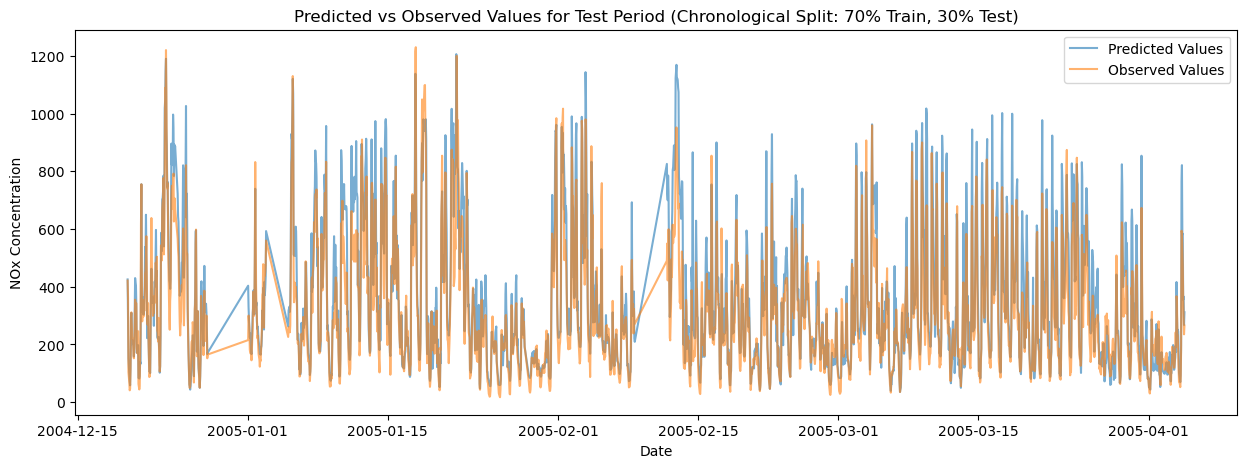

In [21]:
fig, ax = plt.subplots(figsize=(15,5))

y_test_chr.index = clean_aq.index[-len(y_test_chr):]
split_date = y_test_chr.index[0]

ax.plot(y_test_chr.index,y_pred_chr, alpha = 0.6, label = 'Predicted Values')
ax.plot(y_test_chr.index,y_test_chr, alpha = 0.6, label = 'Observed Values')
#ax.axvline(x=split_date, color='red', linestyle='--', linewidth=1.5, label='Train/Test Split')

ax.set_title('Predicted vs Observed Values for Test Period (Chronological Split: 70% Train, 30% Test)')
ax.set_xlabel('Date')
ax.set_ylabel('NOx Concentration')

ax.legend()
plt.show()

_The predicted and reported values are pretty similar, however there does seem to be more prediction error in the later months, especially for March 2005 through April 2005. Generally, yes, the error grows as you move further from the training period. This is likely due sensor degradation over time and seasonal variations of NOx concentrations._

## Part 5: Report

13) In two or three sentences, state the RMSE and $R^2$ you would report for this model and
which validation scheme produced them.

```{admonition} A note on what counts as success
:class: tip
If your chronological score is substantially worse than your first random-split score, that is the
correct result and you should report it as such. The purpose of this assignment is to
measure that gap, not to make it disappear.
```

_I would report an RMSE of 95.02 ppb and an R^2 of 0.80 from the chronological Random Forest model. These metrics were found using a time-based train/test split validation scheme. I choose this scheme because it avoids bias from the temporal autocorrelation of adjacent hours in the the random train/test split and provides an accurate, realistic estimate of how the model will perform when predicting pollution in future months._